# FraudGuard: Credit Card Fraud Detection

## 1. Project Overview

Credit card fraud detection is a binary classification problem where the goal is to identify whether a transaction is legitimate or fraudulent.

In this project, we will work with a real-world credit card transaction dataset containing 284,807 transactions, of which only 492 are fraudulent. This means fraudulent transactions represent only a very small portion of the complete dataset.

This makes the problem challenging because a model could achieve very high accuracy simply by predicting every transaction as legitimate. However, such a model would fail at the actual goal of detecting fraud.

Therefore, this project focuses on handling highly imbalanced data and evaluating the model using metrics that are more meaningful for fraud detection, such as precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC.

### Objectives

- Understand and explore the transaction data
- Analyze the severe class imbalance
- Scale the `Amount` and `Time` features
- Split the data using stratification
- Build a baseline Logistic Regression model
- Handle class imbalance using class weights and SMOTE
- Train a Random Forest classifier
- Compare models using appropriate evaluation metrics
- Tune the classification decision threshold
- Select and evaluate the final model

### Dataset

The dataset used in this project is the **Credit Card Fraud Detection** dataset from Kaggle.

It contains anonymized transaction features along with a `Class` target variable:

- `Class = 0` → Legitimate transaction
- `Class = 1` → Fraudulent transaction

The dataset contains:

- **284,807 total transactions**
- **492 fraudulent transactions**
- Approximately **0.17% fraudulent transactions**

### Why This Project Matters

Fraud detection is a highly imbalanced classification problem. Since fraudulent transactions are extremely rare compared with legitimate transactions, accuracy alone can give a misleading picture of model performance.

For example, a model that predicts every transaction as legitimate could achieve around 99.8% accuracy while detecting zero fraudulent transactions.

Therefore, this project will focus on **precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC** to properly evaluate how well the model detects fraud.

### Key Learning Outcomes

By completing this project, we will learn:

- How to work with highly imbalanced datasets
- Why accuracy can be misleading
- How stratified train-test splitting preserves class proportions
- How feature scaling works
- How class weights can help handle imbalance
- How SMOTE creates synthetic minority-class samples
- How Logistic Regression and Random Forest can be used for fraud detection
- How to evaluate classification models using appropriate metrics
- How decision threshold tuning affects precision and recall

The final goal is not simply to achieve a high accuracy score, but to develop a model that can meaningfully identify fraudulent transactions and justify its performance using appropriate evaluation metrics.


## 2. Import Required Libraries

In [1]:
# Import libraries for data manipulation
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries for data preprocessing and model building
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc
)

# Import SMOTE for handling class imbalance
from imblearn.over_sampling import SMOTE

# Set display options for easier dataset inspection
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Set a consistent style for visualizations
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the Dataset

In [2]:
# Load the credit card fraud dataset
df = pd.read_csv(r"C:\Users\humai\Intern\FraudGuard\Data\creditcard.csv")


## 4. Understand the Dataset

In [3]:
# Display the number of rows and columns
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(284807, 31)


In [4]:
# Display the column names
print("\nColumn Names:")
print(df.columns.tolist())



Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [5]:
# Display basic information about the dataset
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21 

In [6]:

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [7]:
# Check for missing values
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [8]:
# Check for duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())


Number of Duplicate Rows:
1081


In [9]:
# Display statistical summary of numerical columns
print("\nStatistical Summary:")
display(df.describe())


Statistical Summary:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


### Observation

The dataset contains 284,807 transactions and 31 columns. All columns contain 284,807 non-null values, indicating that there are no missing values in the dataset.

The dataset consists mainly of numerical features, with `Class` stored as an integer representing the target variable. The `Time` and `Amount` features are also numerical, while `V1` to `V28` represent anonymized transaction features.

A total of 1,081 duplicate rows were identified. These duplicates will be considered carefully during the preprocessing stage rather than being removed without further investigation.

The statistical summary shows that the numerical features have different distributions and scales. Feature scaling will therefore be important when preparing the data for models such as Logistic Regression.

## 5. Exploratory Data Analysis (EDA)

In [10]:
# Inspect the Target Variable

print("Transaction Class Counts:")
print(df["Class"].value_counts())

Transaction Class Counts:
Class
0    284315
1       492
Name: count, dtype: int64


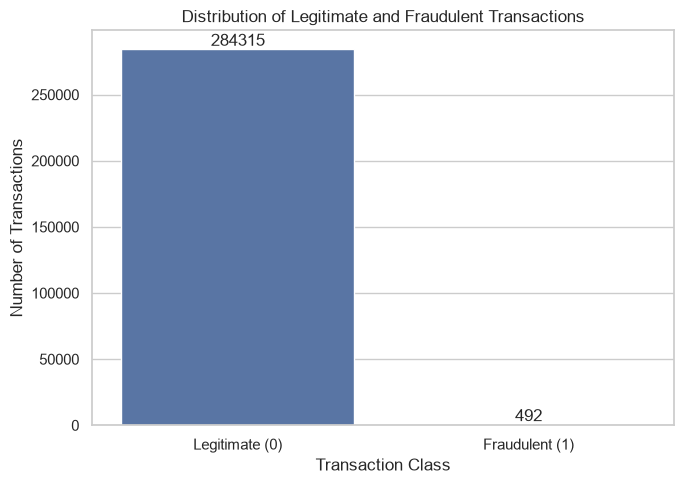

In [11]:
# Visualize Class Distribution

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Class")

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

# Add transaction counts above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.show()

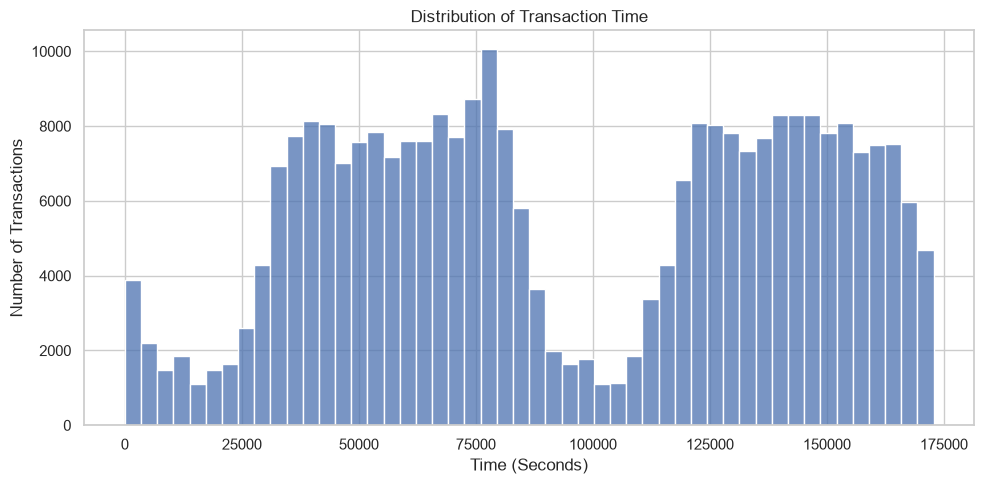

In [12]:
# Analyze Transaction Time

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Time", bins=50)

plt.title("Distribution of Transaction Time")
plt.xlabel("Time (Seconds)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

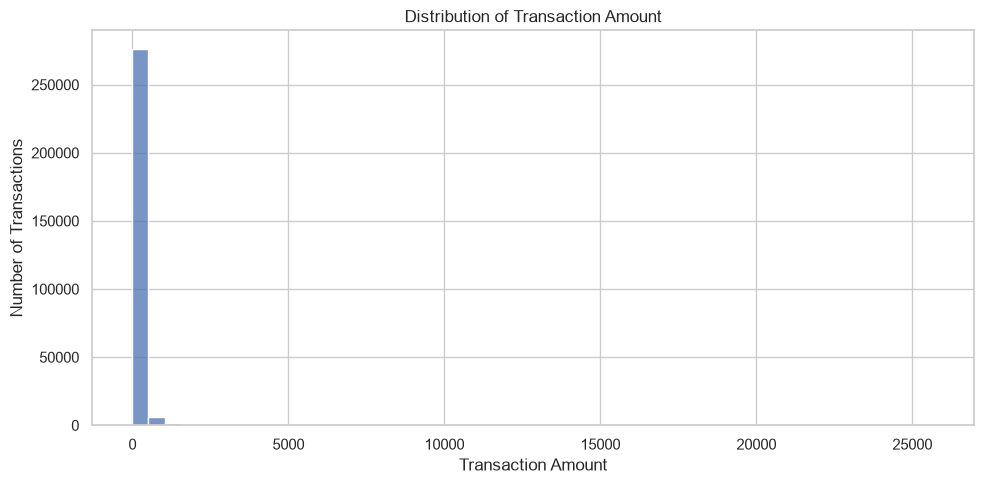

In [13]:
# Analyze Transaction Amount

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Amount", bins=50)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

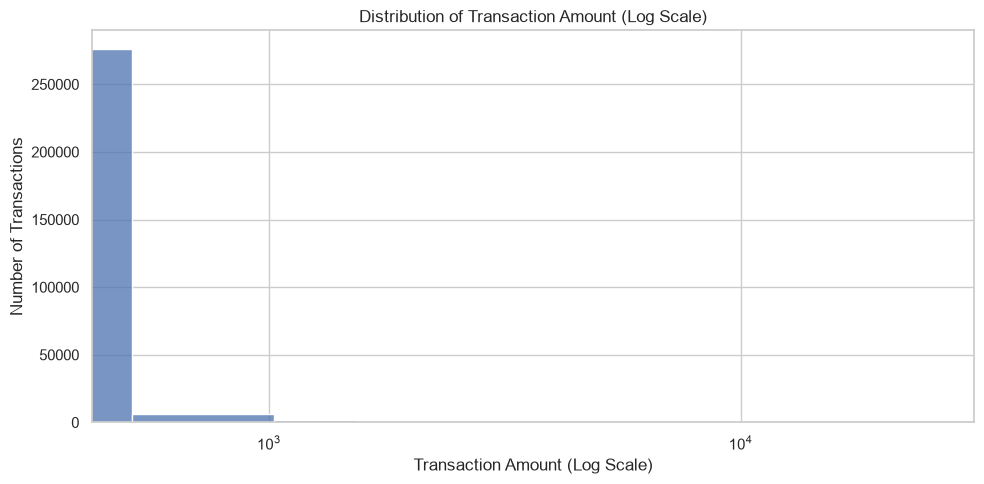

In [14]:
# Transaction Amount Distribution on a Log Scale

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Amount", bins=50)

plt.xscale("log")

plt.title("Distribution of Transaction Amount (Log Scale)")
plt.xlabel("Transaction Amount (Log Scale)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

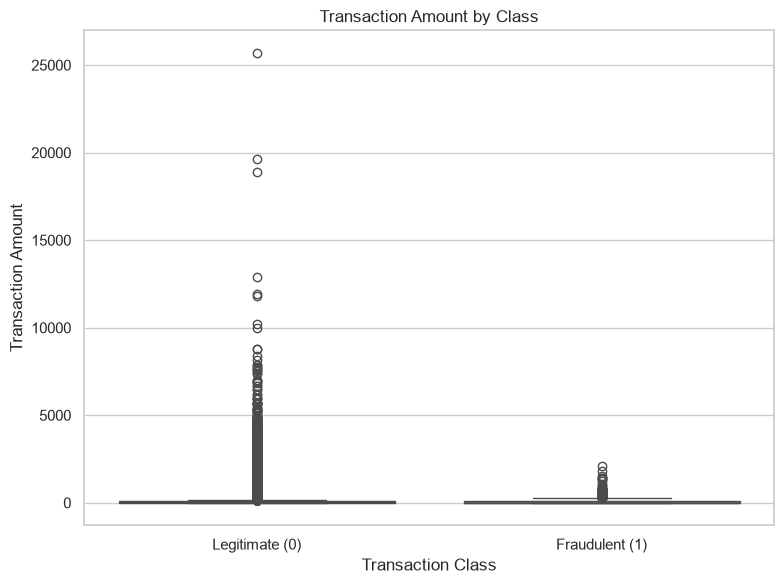

In [15]:
# Transaction Amount by Class
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

plt.tight_layout()
plt.show()

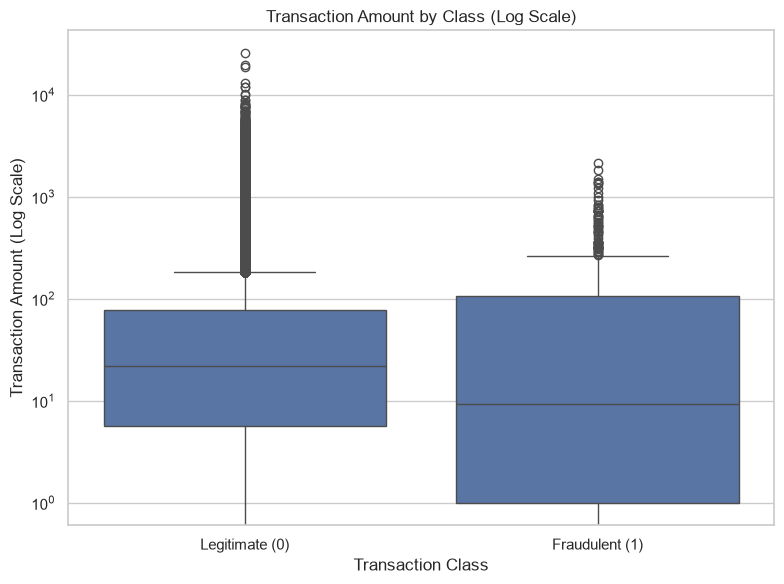

In [16]:
# Transaction Amount by Class — Log Scale

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.yscale("log")

plt.title("Transaction Amount by Class (Log Scale)")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount (Log Scale)")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

plt.tight_layout()
plt.show()

In [17]:
# Correlation Analysis

# Calculate the correlation matrix
correlation_matrix = df.corr()

# Display the correlation of each feature with the target variable
class_correlation = correlation_matrix["Class"].sort_values(ascending=False)

print("Correlation of Features with Class:")
print(class_correlation)

Correlation of Features with Class:
Class     1.000000
V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64


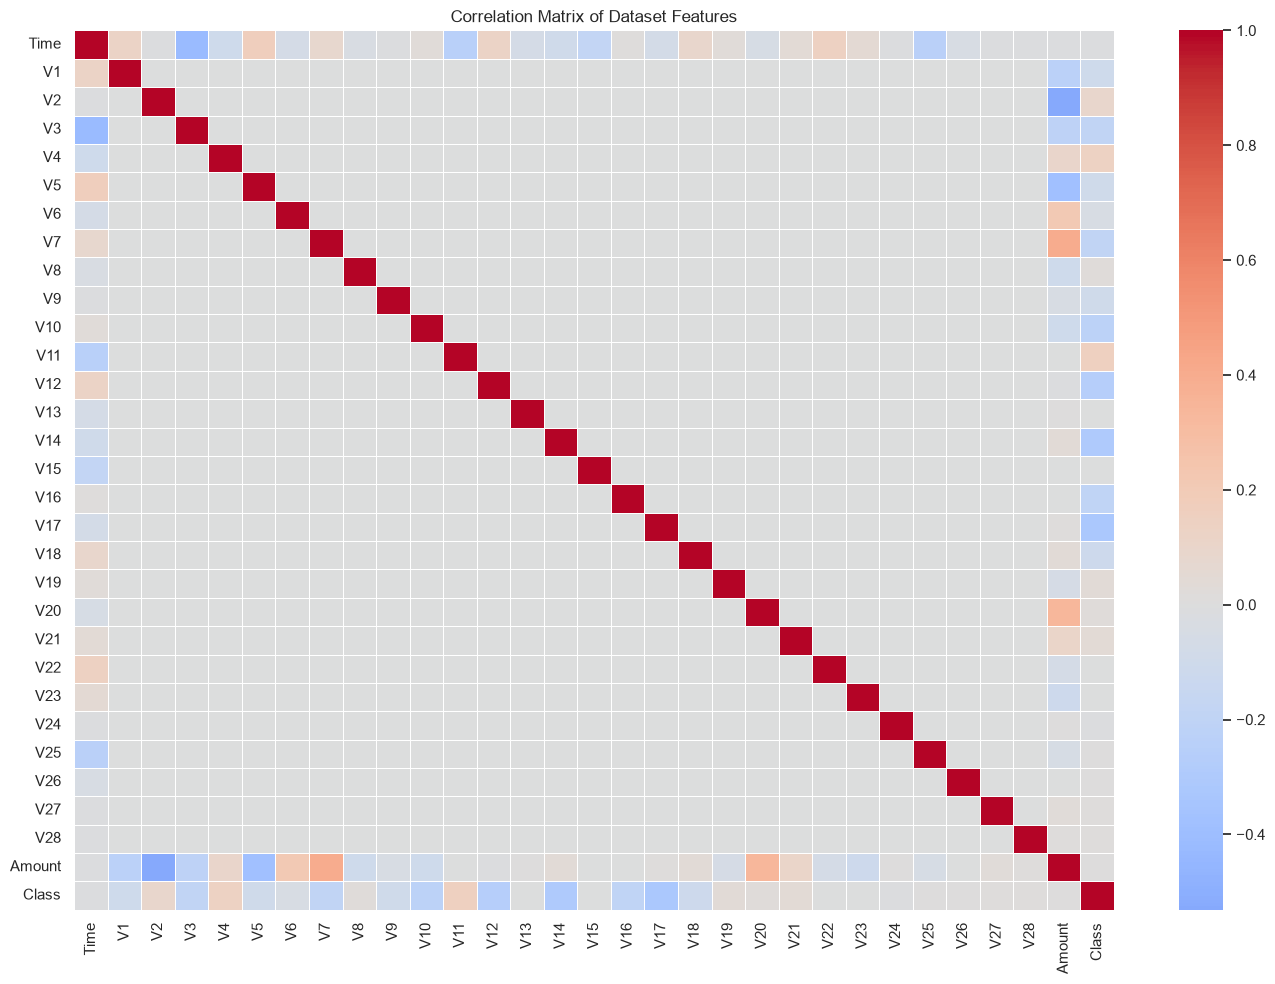

In [18]:
# Visualize the Correlation Matrix

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Dataset Features")
plt.tight_layout()
plt.show()

In [19]:
# Identify Strongest Correlations with Class

# Find the strongest correlations with the target variable
class_correlation_strength = (
    correlation_matrix["Class"]
    .drop("Class")
    .abs()
    .sort_values(ascending=False)
)

print("Features with the Strongest Absolute Correlation with Class:")
print(class_correlation_strength.head(10))

Features with the Strongest Absolute Correlation with Class:
V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
Name: Class, dtype: float64


### EDA Observation

From the exploratory analysis, the biggest thing I noticed is that the dataset is extremely imbalanced. Out of 284,807 transactions, 284,315 are legitimate and only 492 are fraudulent. This means that fraud accounts for just 0.1727% of all transactions.

The `Time` feature shows how the transactions are distributed over the recorded time period, while the `Amount` feature has a wide range of values, with some transactions having much larger amounts than others. The log-scale visualization made it easier to see the distribution of these values.

When comparing transaction amounts for legitimate and fraudulent transactions, the two classes show some differences in their distributions. However, there is still considerable overlap, so `Amount` by itself cannot be used to reliably identify fraud.

The correlation analysis also shows that the anonymized features (`V1` to `V28`) have different relationships with the `Class` variable. Some features show a stronger relationship with fraud, while others have a much weaker linear relationship.

Overall, the EDA makes it clear that the main challenge in this project is the very small number of fraudulent transactions compared with legitimate ones. Because of this imbalance, simply looking at accuracy would not give us a good idea of how well our model detects fraud. We will therefore need to use suitable evaluation metrics and imbalance-handling techniques when building our models.

## 6. Analyze Class Imbalance

Class imbalance occurs when one class contains far more observations than another class.

In this dataset, the two classes are:

- `0` → Legitimate transaction
- `1` → Fraudulent transaction

Fraudulent transactions are extremely rare compared with legitimate transactions. This creates a challenge for machine learning because a model can become biased toward the majority class.

To understand the severity of the imbalance, we will calculate the number and percentage of transactions belonging to each class.

In [20]:
# Count the number of transactions in each class
class_counts = df["Class"].value_counts().sort_index()

print("Class Distribution:")
print(f"Legitimate transactions (0): {class_counts[0]:,}")
print(f"Fraudulent transactions (1): {class_counts[1]:,}")

Class Distribution:
Legitimate transactions (0): 284,315
Fraudulent transactions (1): 492


In [21]:
# Calculate the percentage of each class
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

print("Class Percentage:")
print(f"Legitimate transactions (0): {class_percentages[0]:.4f}%")
print(f"Fraudulent transactions (1): {class_percentages[1]:.4f}%")

Class Percentage:
Legitimate transactions (0): 99.8273%
Fraudulent transactions (1): 0.1727%


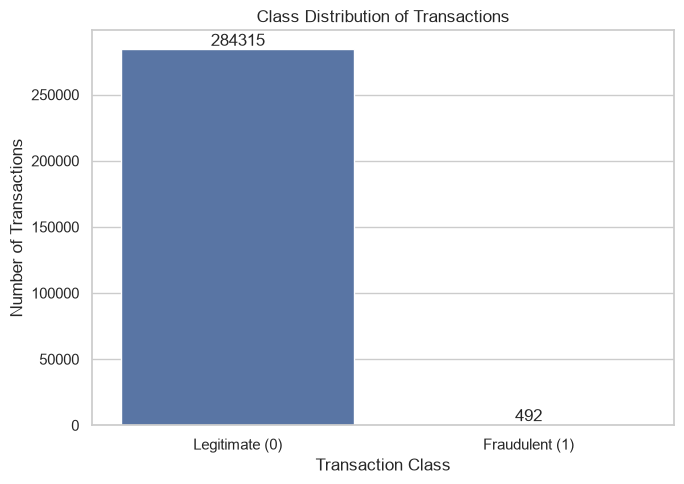

In [22]:
# Visualize the class distribution
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Class")

plt.title("Class Distribution of Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

# Display counts above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.show()

In [23]:
# Calculate the ratio of legitimate transactions to fraudulent transactions
imbalance_ratio = class_counts[0] / class_counts[1]

print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")

Imbalance ratio: 577.88:1


### Observation

The class distribution shows a very severe imbalance in the dataset. There are 284,315 legitimate transactions, making up 99.8273% of the data, while only 492 transactions are fraudulent, representing just 0.1727%.

This means that there are roughly 578 legitimate transactions for every one fraudulent transaction. The difference between the two classes is therefore very large.

Because fraudulent transactions are such a small minority, a machine learning model could easily become biased toward predicting the majority class. This is why we cannot rely on accuracy alone when evaluating our fraud detection models.

The severe imbalance also means that we will need to use an appropriate strategy, such as class weighting or SMOTE, to help the models learn from the minority class more effectively.

## 7. Understand Why Accuracy Is Misleading

Accuracy is the percentage of total predictions that a model gets correct.

In a normal classification problem, accuracy can be a useful metric. However, our fraud detection dataset is highly imbalanced, with fraudulent transactions making up only 0.1727% of the dataset.

Because legitimate transactions make up almost the entire dataset, a model could predict every transaction as legitimate and still achieve very high accuracy.

To demonstrate this problem, we will create a simple hypothetical classifier that predicts every transaction as `0` (legitimate) and calculate its accuracy.

In [24]:
# Create predictions where every transaction is classified as legitimate
all_legitimate_predictions = np.zeros(len(df), dtype=int)

# Calculate the accuracy
all_legitimate_accuracy = accuracy_score(
    df["Class"],
    all_legitimate_predictions
)

print(f"Accuracy of an all-legitimate classifier: {all_legitimate_accuracy:.4f}")
print(f"Accuracy percentage: {all_legitimate_accuracy * 100:.2f}%")

Accuracy of an all-legitimate classifier: 0.9983
Accuracy percentage: 99.83%


In [25]:
# Calculate how many fraudulent transactions were predicted
fraud_detected = (
    (df["Class"] == 1) &
    (all_legitimate_predictions == 1)
).sum()

# Calculate how many fraudulent transactions were missed
fraud_missed = (
    (df["Class"] == 1) &
    (all_legitimate_predictions == 0)
).sum()

print("Fraudulent transactions actually present:", (df["Class"] == 1).sum())
print("Fraudulent transactions detected:", fraud_detected)
print("Fraudulent transactions missed:", fraud_missed)

Fraudulent transactions actually present: 492
Fraudulent transactions detected: 0
Fraudulent transactions missed: 492


In [26]:
# Calculate precision and recall for the all-legitimate classifier
baseline_precision = precision_score(
    df["Class"],
    all_legitimate_predictions,
    zero_division=0
)

baseline_recall = recall_score(
    df["Class"],
    all_legitimate_predictions,
    zero_division=0
)

baseline_f1 = f1_score(
    df["Class"],
    all_legitimate_predictions,
    zero_division=0
)

print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")

Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000


In [27]:
# Generate the confusion matrix
baseline_cm = confusion_matrix(
    df["Class"],
    all_legitimate_predictions
)

print("Confusion Matrix:")
print(baseline_cm)

Confusion Matrix:
[[284315      0]
 [   492      0]]


### Key Concept

This simple example shows why accuracy can be misleading for highly imbalanced data.

A model can achieve very high accuracy simply by predicting the majority class, while completely failing to detect the minority class.

For fraud detection, missing an actual fraudulent transaction is much more important than simply maximizing the number of correct predictions.

Therefore, throughout this project, we will focus more heavily on:

- **Precision** — How many predicted fraud cases are actually fraud?
- **Recall** — How many actual fraud cases are detected?
- **F1-score** — Balance between precision and recall.
- **ROC-AUC** — Ability to distinguish between the two classes.
- **Precision-Recall AUC** — Useful for evaluating performance on highly imbalanced data.

The goal is to build a model that actually detects fraudulent transactions rather than simply achieving a high accuracy score.

### Observation

The all-legitimate classifier demonstrates why accuracy is not suitable as the main evaluation metric for this problem. Even though the classifier achieves very high accuracy, it fails to detect any of the 492 fraudulent transactions.

Its recall and F1-score for the fraud class are both 0, showing that the model is completely ineffective at identifying fraud.

This example makes the class imbalance problem clear: because legitimate transactions account for 99.8273% of the dataset, a model can appear highly accurate simply by predicting the majority class.

Therefore, when we build our actual machine learning models, we will focus on precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC instead of relying on accuracy alone.

## 8. Scale Amount and Time Features

The `Time` and `Amount` features have different numerical ranges from the other features in the dataset.

Feature scaling is useful for models such as Logistic Regression because it puts numerical features on a more comparable scale.

We will use `StandardScaler` to standardize the `Time` and `Amount` features.

Standardization transforms the values so that the feature has a mean close to 0 and a standard deviation close to 1.

However, the scaler should not be fitted using the complete dataset. If we calculate the scaling parameters using both training and testing data, information from the test set could influence the model-building process.

Therefore, the correct approach is:

1. Split the data into training and testing sets.
2. Fit the scaler using only the training data.
3. Transform the training data using the fitted scaler.
4. Transform the testing data using the same scaler.

The actual scaling will be performed after the stratified train-test split.

### Why Scale `Time` and `Amount`?

The `V1` to `V28` features in this dataset have already been transformed and are generally on comparable numerical scales.

The `Time` and `Amount` features are different because they have not gone through the same transformation.

Therefore, according to the project requirements, we will specifically scale:

- `Time`
- `Amount`

We will leave the anonymized `V1` to `V28` features unchanged.

### Scaling Method

We will use `StandardScaler` from scikit-learn.

The scaler will learn the mean and standard deviation from the training data only. The same learned values will then be used to transform both the training and testing data.

This ensures that the test data remains completely unseen during the fitting process and prevents data leakage.

## 9. Train-Test Split with Stratification

Before training our machine learning models, we need to divide the dataset into a training set and a testing set.

We will use:

- **80% of the data for training**
- **20% of the data for testing**

Since the dataset is highly imbalanced, we will use **stratified splitting**. This preserves the proportion of legitimate and fraudulent transactions in both datasets.

After splitting, we will scale the `Time` and `Amount` features.

To avoid data leakage, the `StandardScaler` will be fitted only on the training data. The same fitted scaler will then be used to transform the testing data.

In [28]:
# Separate the input features and target variable
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [29]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Training target  :", y_train.shape)
print("Testing target   :", y_test.shape)

Training features: (227845, 30)
Testing features : (56962, 30)
Training target  : (227845,)
Testing target   : (56962,)


In [30]:
# Check class distribution in the original, training, and testing datasets
print("Original Dataset:")
print(y.value_counts())
print((y.value_counts(normalize=True) * 100).round(4))

print("\nTraining Dataset:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(4))

print("\nTesting Dataset:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(4))

Original Dataset:
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64

Training Dataset:
Class
0    227451
1       394
Name: count, dtype: int64
Class
0    99.8271
1     0.1729
Name: proportion, dtype: float64

Testing Dataset:
Class
0    56864
1       98
Name: count, dtype: int64
Class
0    99.828
1     0.172
Name: proportion, dtype: float64


In [31]:
# Create a StandardScaler
scaler = StandardScaler()

# Make copies so the original training and testing data remain unchanged
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit the scaler only on the training data and transform it
X_train_scaled[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

# Use the same fitted scaler to transform the testing data
X_test_scaled[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

print("Time and Amount features have been scaled successfully.")

Time and Amount features have been scaled successfully.


In [32]:
# Check the statistics of the scaled features
print("Scaled Training Features:")
display(X_train_scaled[["Time", "Amount"]].describe())

print("\nScaled Testing Features:")
display(X_test_scaled[["Time", "Amount"]].describe())

Scaled Training Features:


,Time,Amount
count,2.278450e+05,2.278450e+05
mean,-1.409578e-16,3.742243e-17
std,1.000002e+00,1.000002e+00
min,-1.998073e+00,-3.516894e-01
25%,-8.561495e-01,-3.291944e-01
50%,-2.122647e-01,-2.639429e-01
75%,9.366285e-01,-4.262209e-02
max,1.640549e+00,1.021170e+02



Scaled Testing Features:


,Time,Amount
count,56962.000000,56962.000000
mean,-0.007500,0.003456
std,0.999960,0.987933
min,-1.998031,-0.351689
25%,-0.858977,-0.329753
50%,-0.219182,-0.263943
75%,0.931985,-0.046451
max,1.640423,51.143302


### Observation

The dataset was successfully divided into training and testing sets using an 80:20 split. Stratification was used to preserve the proportion of legitimate and fraudulent transactions in both sets.

The class distribution in the training and testing datasets remains very close to the original distribution, which is important because fraudulent transactions are extremely rare.

The `Time` and `Amount` features were then standardized using `StandardScaler`. The scaler was fitted only on the training data and then applied to both training and testing data. This prevents information from the testing set from leaking into the model training process.

The resulting `X_train_scaled` and `X_test_scaled` datasets will be used for the upcoming machine learning models.

## 10. Baseline Logistic Regression

Logistic Regression is a commonly used classification algorithm that estimates the probability of an observation belonging to a particular class.

In this project, the model will predict:

- `0` → Legitimate transaction
- `1` → Fraudulent transaction

We will first train a standard Logistic Regression model without applying any special class-imbalance technique.

This model will serve as our **baseline model**. Later, we will compare its performance with models that use class weights, SMOTE, and Random Forest.

Since the dataset is highly imbalanced, we expect the baseline model to potentially favor the majority class. This will help us understand why imbalance-handling techniques are necessary.

In [33]:
# Create the baseline Logistic Regression model
baseline_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the scaled training data
baseline_lr.fit(X_train_scaled, y_train)

print("Baseline Logistic Regression model trained successfully.")

Baseline Logistic Regression model trained successfully.


In [34]:
# Generate predictions for the test set
baseline_y_pred = baseline_lr.predict(X_test_scaled)

# Generate predicted probabilities for the positive class (fraud)
baseline_y_prob = baseline_lr.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")
print("Number of test predictions:", len(baseline_y_pred))

Predictions generated successfully.
Number of test predictions: 56962


In [35]:
# Calculate baseline evaluation metrics
baseline_accuracy = accuracy_score(y_test, baseline_y_pred)
baseline_precision = precision_score(y_test, baseline_y_pred, zero_division=0)
baseline_recall = recall_score(y_test, baseline_y_pred, zero_division=0)
baseline_f1 = f1_score(y_test, baseline_y_pred, zero_division=0)
baseline_roc_auc = roc_auc_score(y_test, baseline_y_prob)
baseline_pr_auc = average_precision_score(y_test, baseline_y_prob)

# Display the results
print("Baseline Logistic Regression Results")
print("-" * 40)
print(f"Accuracy          : {baseline_accuracy:.4f}")
print(f"Precision         : {baseline_precision:.4f}")
print(f"Recall            : {baseline_recall:.4f}")
print(f"F1-Score          : {baseline_f1:.4f}")
print(f"ROC-AUC           : {baseline_roc_auc:.4f}")
print(f"Precision-Recall AUC: {baseline_pr_auc:.4f}")

Baseline Logistic Regression Results
----------------------------------------
Accuracy          : 0.9992
Precision         : 0.8289
Recall            : 0.6429
F1-Score          : 0.7241
ROC-AUC           : 0.9559
Precision-Recall AUC: 0.7432


In [36]:
# Display the classification report
print("Classification Report:")
print(classification_report(
    y_test,
    baseline_y_pred,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
  Fraudulent       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



In [37]:
# Calculate and display the baseline confusion matrix
baseline_cm = confusion_matrix(y_test, baseline_y_pred)

print("Baseline Confusion Matrix:")
print(baseline_cm)

Baseline Confusion Matrix:
[[56851    13]
 [   35    63]]


### Observation

The baseline Logistic Regression model achieved an accuracy of 99.92%, which looks extremely high at first. However, because the dataset is highly imbalanced, accuracy alone does not give us the complete picture.

For the fraudulent class, the model achieved a precision of 82.89%, meaning that most transactions predicted as fraudulent were actually fraudulent. Its recall was 64.29%, which means the model successfully detected 63 out of the 98 fraudulent transactions in the test set, while missing 35 fraudulent transactions.

The confusion matrix shows that the model correctly classified 56,851 legitimate transactions and incorrectly flagged only 13 legitimate transactions as fraud. At the same time, it correctly detected 63 fraudulent transactions but missed 35.

The model achieved a ROC-AUC of 0.9559, showing that it has a strong ability to distinguish between legitimate and fraudulent transactions. Its Precision-Recall AUC was 0.7432, which provides a more useful view of performance given the severe class imbalance.

Overall, the baseline Logistic Regression model performs reasonably well, but its recall of 64.29% means that a significant number of fraudulent transactions are still being missed. This gives us a clear reason to explore techniques for handling class imbalance in the next stages of the project.

## 11. Handle Class Imbalance using Class Weights

One way to handle class imbalance is to assign different weights to the classes during model training.

In our dataset, fraudulent transactions are much less common than legitimate transactions. A standard Logistic Regression model may therefore give more importance to the majority class.

Using `class_weight="balanced"` automatically assigns higher weight to the minority class and lower weight to the majority class based on their frequencies.

This does not create new data. Instead, it changes how mistakes made on each class are treated during training.

The goal is to encourage the model to pay more attention to fraudulent transactions and potentially improve fraud detection, especially recall.

We will train another Logistic Regression model using class weights and compare its performance with our baseline model.

In [38]:
# Create a Logistic Regression model with balanced class weights
weighted_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
weighted_lr.fit(X_train_scaled, y_train)

print("Class-weighted Logistic Regression model trained successfully.")

Class-weighted Logistic Regression model trained successfully.


In [39]:
# Generate class predictions for the test set
weighted_y_pred = weighted_lr.predict(X_test_scaled)

# Generate fraud probabilities
weighted_y_prob = weighted_lr.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [40]:
# Calculate evaluation metrics
weighted_accuracy = accuracy_score(y_test, weighted_y_pred)
weighted_precision = precision_score(y_test, weighted_y_pred, zero_division=0)
weighted_recall = recall_score(y_test, weighted_y_pred, zero_division=0)
weighted_f1 = f1_score(y_test, weighted_y_pred, zero_division=0)
weighted_roc_auc = roc_auc_score(y_test, weighted_y_prob)
weighted_pr_auc = average_precision_score(y_test, weighted_y_prob)

# Display the results
print("Class-Weighted Logistic Regression Results")
print("-" * 45)
print(f"Accuracy           : {weighted_accuracy:.4f}")
print(f"Precision          : {weighted_precision:.4f}")
print(f"Recall             : {weighted_recall:.4f}")
print(f"F1-Score           : {weighted_f1:.4f}")
print(f"ROC-AUC            : {weighted_roc_auc:.4f}")
print(f"Precision-Recall AUC: {weighted_pr_auc:.4f}")

Class-Weighted Logistic Regression Results
---------------------------------------------
Accuracy           : 0.9755
Precision          : 0.0610
Recall             : 0.9184
F1-Score           : 0.1144
ROC-AUC            : 0.9722
Precision-Recall AUC: 0.7159


In [41]:
# Display the classification report
print("Classification Report:")
print(
    classification_report(
        y_test,
        weighted_y_pred,
        target_names=["Legitimate", "Fraudulent"],
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
  Fraudulent       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [42]:
# Calculate the confusion matrix
weighted_cm = confusion_matrix(y_test, weighted_y_pred)

print("Class-Weighted Logistic Regression Confusion Matrix:")
print(weighted_cm)

Class-Weighted Logistic Regression Confusion Matrix:
[[55478  1386]
 [    8    90]]


In [43]:
# Create a comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        weighted_accuracy
    ],
    "Precision": [
        baseline_precision,
        weighted_precision
    ],
    "Recall": [
        baseline_recall,
        weighted_recall
    ],
    "F1-Score": [
        baseline_f1,
        weighted_f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        weighted_roc_auc
    ],
    "PR-AUC": [
        baseline_pr_auc,
        weighted_pr_auc
    ]
})

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.9992,0.8289,0.6429,0.7241,0.9559,0.7432
1,Class-Weighted Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.9722,0.7159


### Observation

The class-weighted Logistic Regression model shows a very different behavior compared with the baseline model.

The recall for fraudulent transactions increased from 64.29% in the baseline model to 91.84% after applying class weights. This means that the model was able to detect 90 out of the 98 fraudulent transactions in the test set, missing only 8 fraud cases.

However, this improvement in recall came with a large decrease in precision. Precision dropped from 82.89% to 6.10%. The confusion matrix shows why: the model incorrectly classified 1,386 legitimate transactions as fraudulent.

The overall accuracy also decreased from 99.92% to 97.55%. In this case, the decrease in accuracy is not necessarily a problem because our main goal is to detect fraudulent transactions rather than simply maximize the number of correct predictions.

The ROC-AUC increased from 0.9559 to 0.9722, showing that the class-weighted model has strong overall discrimination ability. However, the Precision-Recall AUC decreased slightly from 0.7432 to 0.7159.

Overall, class weighting successfully made the model much more sensitive to fraudulent transactions. However, it also produced a large number of false positives, which resulted in very low precision. This shows the important trade-off between recall and precision in fraud detection and gives us a reason to explore other imbalance-handling approaches such as SMOTE.

## 12. Handle Class Imbalance using SMOTE

SMOTE stands for **Synthetic Minority Over-sampling Technique**.

Our dataset contains far fewer fraudulent transactions than legitimate transactions. This makes it difficult for a machine learning model to learn the patterns of the minority fraud class.

SMOTE addresses this by creating new **synthetic examples** of the minority class based on existing minority-class observations.

The important point is that SMOTE does not simply duplicate the existing fraud transactions. Instead, it generates new synthetic observations based on nearby fraud examples.

We will apply SMOTE only to the **training data**.

The test data will remain completely unchanged because it should represent unseen real-world transactions. Applying SMOTE to the test data would give us an unrealistic evaluation.

Our workflow will therefore be:

1. Start with the already split training data.
2. Apply SMOTE to the training data.
3. Keep the testing data unchanged.
4. Train Logistic Regression using the SMOTE-balanced training data.
5. Evaluate the model on the original, imbalanced test set.

In [44]:
# Display the original training class distribution
print("Original Training Set:")
print(y_train.value_counts())

print("\nOriginal Training Set Percentage:")
print((y_train.value_counts(normalize=True) * 100).round(4))

Original Training Set:
Class
0    227451
1       394
Name: count, dtype: int64

Original Training Set Percentage:
Class
0    99.8271
1     0.1729
Name: proportion, dtype: float64


In [45]:
# Create the SMOTE object
smote = SMOTE(
    random_state=42
)

# Generate synthetic minority-class samples
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("SMOTE applied successfully.")

SMOTE applied successfully.


In [46]:
# Check the class distribution after applying SMOTE
print("Training Set After SMOTE:")
print(y_train_smote.value_counts())

print("\nTraining Set Percentage After SMOTE:")
print((y_train_smote.value_counts(normalize=True) * 100).round(4))

Training Set After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

Training Set Percentage After SMOTE:
Class
0    50.0
1    50.0
Name: proportion, dtype: float64


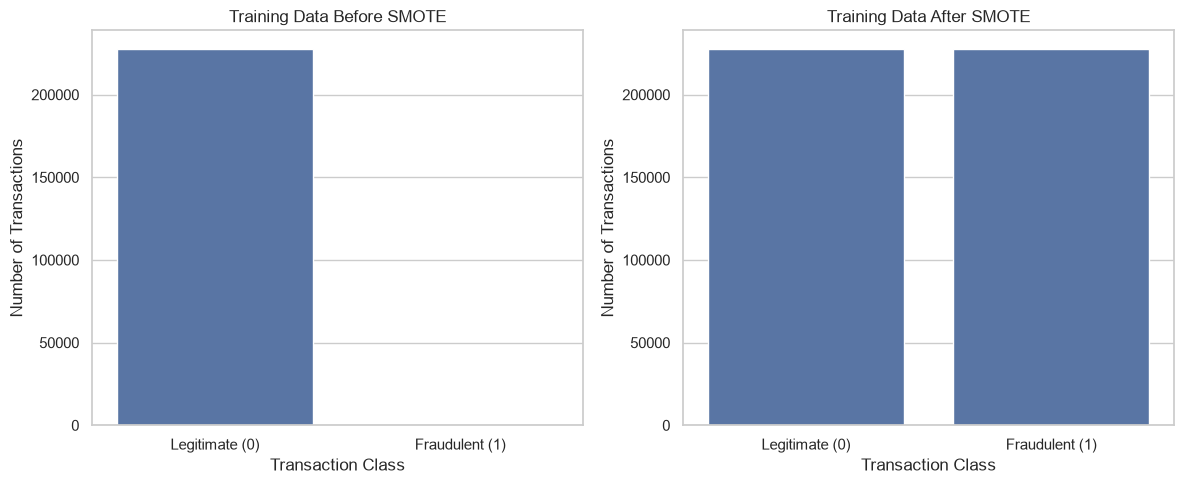

In [47]:
# Create a figure with two separate plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Before SMOTE
sns.countplot(
    x=y_train,
    ax=axes[0]
)

axes[0].set_title("Training Data Before SMOTE")
axes[0].set_xlabel("Transaction Class")
axes[0].set_ylabel("Number of Transactions")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Legitimate (0)", "Fraudulent (1)"])

# After SMOTE
sns.countplot(
    x=y_train_smote,
    ax=axes[1]
)

axes[1].set_title("Training Data After SMOTE")
axes[1].set_xlabel("Transaction Class")
axes[1].set_ylabel("Number of Transactions")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Legitimate (0)", "Fraudulent (1)"])

plt.tight_layout()
plt.show()

### Logistic Regression with SMOTE

We will now train Logistic Regression using the SMOTE-balanced training data.

The model will learn from both the original legitimate transactions and the synthetic fraudulent transactions created by SMOTE.

The testing data will remain unchanged, allowing us to evaluate the model on the original class distribution.

In [48]:
# Create Logistic Regression model
smote_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the SMOTE-balanced training data
smote_lr.fit(
    X_train_smote,
    y_train_smote
)

print("SMOTE Logistic Regression model trained successfully.")

SMOTE Logistic Regression model trained successfully.


In [49]:
# Generate predictions on the original test data
smote_y_pred = smote_lr.predict(X_test_scaled)

# Generate fraud probabilities
smote_y_prob = smote_lr.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [50]:
# Calculate evaluation metrics
smote_accuracy = accuracy_score(y_test, smote_y_pred)
smote_precision = precision_score(y_test, smote_y_pred, zero_division=0)
smote_recall = recall_score(y_test, smote_y_pred, zero_division=0)
smote_f1 = f1_score(y_test, smote_y_pred, zero_division=0)
smote_roc_auc = roc_auc_score(y_test, smote_y_prob)
smote_pr_auc = average_precision_score(y_test, smote_y_prob)

# Display the results
print("SMOTE Logistic Regression Results")
print("-" * 45)
print(f"Accuracy            : {smote_accuracy:.4f}")
print(f"Precision           : {smote_precision:.4f}")
print(f"Recall              : {smote_recall:.4f}")
print(f"F1-Score            : {smote_f1:.4f}")
print(f"ROC-AUC             : {smote_roc_auc:.4f}")
print(f"Precision-Recall AUC: {smote_pr_auc:.4f}")

SMOTE Logistic Regression Results
---------------------------------------------
Accuracy            : 0.9742
Precision           : 0.0580
Recall              : 0.9184
F1-Score            : 0.1092
ROC-AUC             : 0.9699
Precision-Recall AUC: 0.7249


In [51]:
# Display the classification report
print("SMOTE Logistic Regression Classification Report:")

print(
    classification_report(
        y_test,
        smote_y_pred,
        target_names=["Legitimate", "Fraudulent"],
        zero_division=0
    )
)

SMOTE Logistic Regression Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
  Fraudulent       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



In [52]:
# Calculate the confusion matrix
smote_cm = confusion_matrix(
    y_test,
    smote_y_pred
)

print("SMOTE Logistic Regression Confusion Matrix:")
print(smote_cm)

SMOTE Logistic Regression Confusion Matrix:
[[55403  1461]
 [    8    90]]


In [53]:
# Add the SMOTE model to our existing comparison table
smote_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression",
        "SMOTE Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        weighted_accuracy,
        smote_accuracy
    ],
    "Precision": [
        baseline_precision,
        weighted_precision,
        smote_precision
    ],
    "Recall": [
        baseline_recall,
        weighted_recall,
        smote_recall
    ],
    "F1-Score": [
        baseline_f1,
        weighted_f1,
        smote_f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        weighted_roc_auc,
        smote_roc_auc
    ],
    "PR-AUC": [
        baseline_pr_auc,
        weighted_pr_auc,
        smote_pr_auc
    ]
})

display(smote_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.9992,0.8289,0.6429,0.7241,0.9559,0.7432
1,Class-Weighted Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.9722,0.7159
2,SMOTE Logistic Regression,0.9742,0.0580,0.9184,0.1092,0.9699,0.7249


### Observation

After applying SMOTE, the training data became balanced between the legitimate and fraudulent classes. Importantly, SMOTE was applied only to the training data, while the original test data was kept unchanged for a fair evaluation.

The SMOTE Logistic Regression model achieved an accuracy of 97.42%, but accuracy is not the main metric we are interested in for this problem.

The model achieved a recall of 91.84% for fraudulent transactions, detecting 90 out of the 98 fraudulent transactions in the test set and missing only 8. This is the same recall achieved by the class-weighted Logistic Regression model.

However, the precision was only 5.80%, meaning that a large number of transactions predicted as fraudulent were actually legitimate. The confusion matrix confirms this, with 1,461 legitimate transactions incorrectly classified as fraud.

Compared with the class-weighted model, SMOTE produced almost the same recall, but its precision was slightly lower (5.80% compared with 6.10%). Its F1-score was also slightly lower, at 10.92% compared with 11.44%.

The SMOTE model achieved a ROC-AUC of 0.9699 and a PR-AUC of 0.7249. The PR-AUC was slightly higher than the class-weighted model's 0.7159 but lower than the baseline model's 0.7432.

Overall, SMOTE successfully increased the model's ability to detect fraudulent transactions, but it also resulted in a large number of false positives. This shows that balancing the training data alone does not automatically produce the best-performing fraud detection model. We will continue comparing different approaches before selecting the final model.

## 13. Random Forest Classifier

Random Forest is an ensemble machine learning algorithm that combines the predictions of multiple decision trees.

Instead of relying on a single decision tree, Random Forest builds many trees and combines their predictions to produce a final result. This can help the model capture more complex relationships between features.

In this project, we will use Random Forest to see whether a tree-based model can identify fraudulent transactions more effectively than our Logistic Regression approaches.

We will train the model using the original training data first. The testing data will remain unchanged and will only be used for evaluation.

The model will also produce fraud probabilities, which we will use later for ROC-AUC, Precision-Recall AUC, and decision threshold tuning.

In [54]:
# Create the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [55]:
# Generate class predictions for the test set
rf_y_pred = rf_model.predict(X_test_scaled)

# Generate fraud probabilities
rf_y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("Random Forest predictions generated successfully.")

Random Forest predictions generated successfully.


In [56]:
# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_precision = precision_score(y_test, rf_y_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_y_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_y_pred, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, rf_y_prob)
rf_pr_auc = average_precision_score(y_test, rf_y_prob)

# Display the results
print("Random Forest Results")
print("-" * 40)
print(f"Accuracy            : {rf_accuracy:.4f}")
print(f"Precision           : {rf_precision:.4f}")
print(f"Recall              : {rf_recall:.4f}")
print(f"F1-Score            : {rf_f1:.4f}")
print(f"ROC-AUC             : {rf_roc_auc:.4f}")
print(f"Precision-Recall AUC: {rf_pr_auc:.4f}")

Random Forest Results
----------------------------------------
Accuracy            : 0.9996
Precision           : 0.9412
Recall              : 0.8163
F1-Score            : 0.8743
ROC-AUC             : 0.9630
Precision-Recall AUC: 0.8734


In [57]:
# Display the classification report
print("Random Forest Classification Report:")

print(
    classification_report(
        y_test,
        rf_y_pred,
        target_names=["Legitimate", "Fraudulent"],
        zero_division=0
    )
)

Random Forest Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
  Fraudulent       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962



In [58]:
# Calculate the Random Forest confusion matrix
rf_cm = confusion_matrix(
    y_test,
    rf_y_pred
)

print("Random Forest Confusion Matrix:")
print(rf_cm)

Random Forest Confusion Matrix:
[[56859     5]
 [   18    80]]


### Observation

The Random Forest model performed noticeably better than the Logistic Regression approaches at the default classification threshold of 0.5.

The model achieved an accuracy of 99.96%, but the more important results are its fraud-class precision of 94.12% and recall of 81.63%. This means that the model correctly identified 80 out of the 98 fraudulent transactions in the test set while missing 18 fraud cases.

The confusion matrix shows that only 5 legitimate transactions were incorrectly classified as fraudulent, while 18 fraudulent transactions were classified as legitimate. This is a much smaller number of false positives compared with the class-weighted and SMOTE Logistic Regression models.

The F1-score for the fraudulent class was 87.43%, which shows a much better balance between precision and recall compared with the previous Logistic Regression approaches.

The Random Forest model also achieved a ROC-AUC of 0.9630 and a Precision-Recall AUC of 0.8734. Its Precision-Recall AUC is higher than the values obtained by the three Logistic Regression approaches tested so far.

Overall, Random Forest currently provides the strongest balance between detecting fraudulent transactions and avoiding false alarms. However, we will not select the final model yet because we still need to compare all models systematically and tune the decision threshold.

## 14. Model Evaluation and Comparison

We have now trained four different models using different approaches to the class imbalance problem.

To compare them fairly, we will examine the same evaluation metrics for every model:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Precision-Recall AUC

Accuracy is included for completeness, but it will not be the main factor in deciding which model performs best.

For this fraud detection problem, we are particularly interested in the balance between precision and recall, along with ROC-AUC and Precision-Recall AUC.

In [59]:
# Create a comparison table for all four models
final_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression",
        "SMOTE Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        baseline_accuracy,
        weighted_accuracy,
        smote_accuracy,
        rf_accuracy
    ],
    "Precision": [
        baseline_precision,
        weighted_precision,
        smote_precision,
        rf_precision
    ],
    "Recall": [
        baseline_recall,
        weighted_recall,
        smote_recall,
        rf_recall
    ],
    "F1-Score": [
        baseline_f1,
        weighted_f1,
        smote_f1,
        rf_f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        weighted_roc_auc,
        smote_roc_auc,
        rf_roc_auc
    ],
    "PR-AUC": [
        baseline_pr_auc,
        weighted_pr_auc,
        smote_pr_auc,
        rf_pr_auc
    ]
})

display(final_model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.9992,0.8289,0.6429,0.7241,0.9559,0.7432
1,Class-Weighted Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.9722,0.7159
2,SMOTE Logistic Regression,0.9742,0.0580,0.9184,0.1092,0.9699,0.7249
3,Random Forest,0.9996,0.9412,0.8163,0.8743,0.9630,0.8734


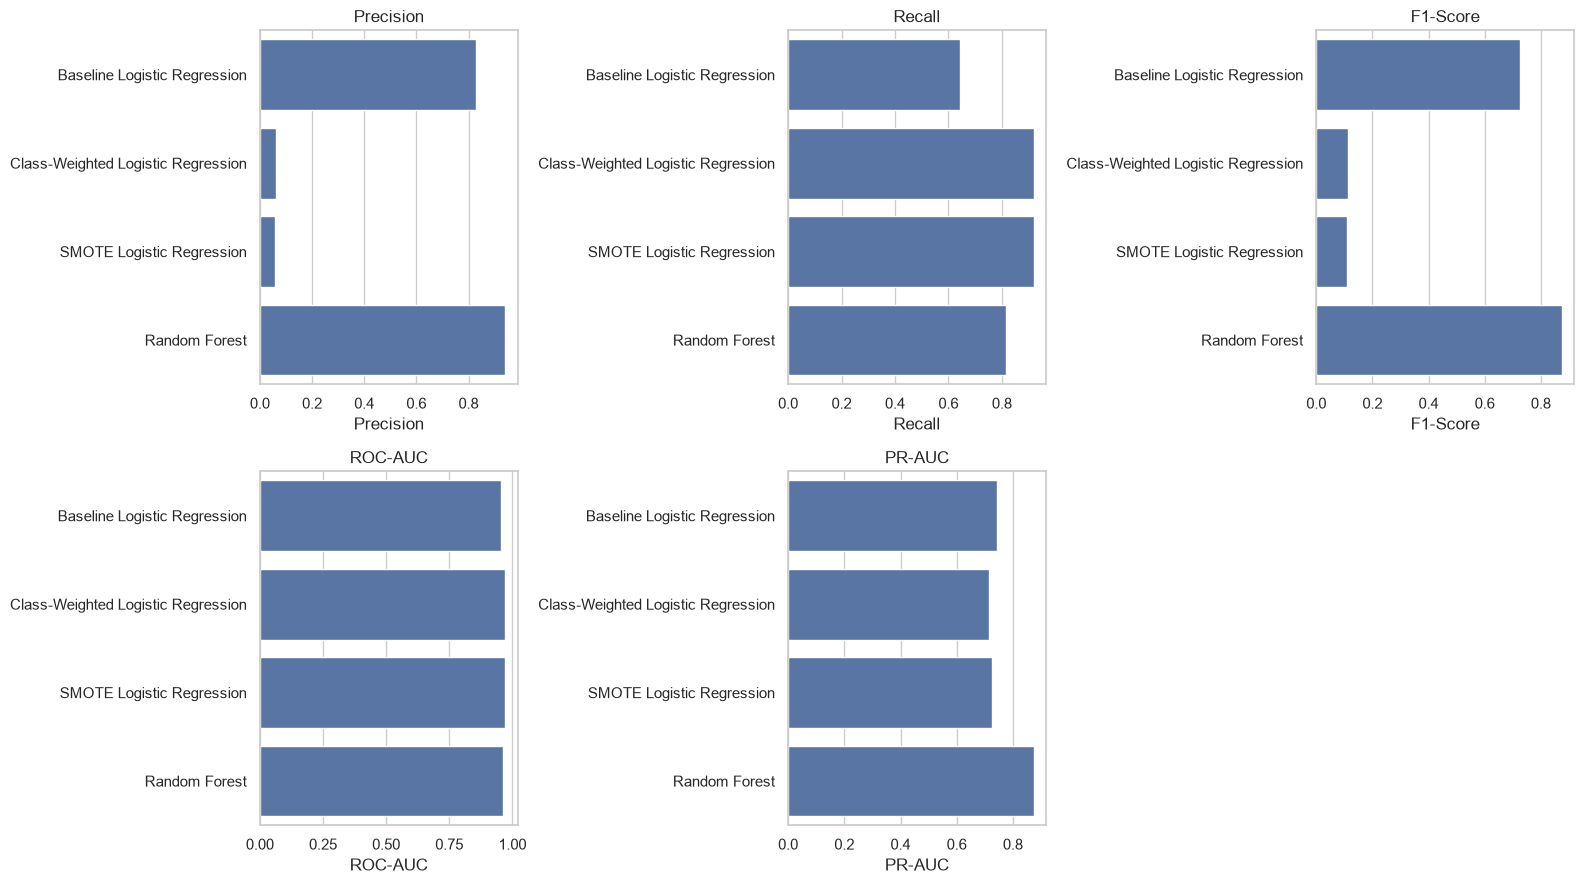

In [60]:
# Select the metrics we want to compare
metrics = [
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

# Create a figure
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Create one plot for each metric
for ax, metric in zip(axes.flat, metrics):
    sns.barplot(
        data=final_model_comparison,
        x=metric,
        y="Model",
        ax=ax
    )
    
    ax.set_title(metric)
    ax.set_xlabel(metric)
    ax.set_ylabel("")

# Remove the unused sixth subplot
fig.delaxes(axes.flat[5])

plt.tight_layout()
plt.show()

In [61]:
# Compare precision and recall for the fraudulent class
precision_recall_comparison = final_model_comparison[
    ["Model", "Precision", "Recall"]
].copy()

display(precision_recall_comparison.round(4))

,Model,Precision,Recall
0,Baseline Logistic Regression,0.8289,0.6429
1,Class-Weighted Logistic Regression,0.0610,0.9184
2,SMOTE Logistic Regression,0.0580,0.9184
3,Random Forest,0.9412,0.8163


### Understanding the Model Comparison

The four models behave quite differently because they handle the class imbalance in different ways.

The baseline Logistic Regression model has high precision but lower recall. This means that when it predicts fraud, it is usually correct, but it misses a considerable number of fraudulent transactions.

The class-weighted Logistic Regression model increases recall significantly. However, it also produces many false positives, which causes its precision to become very low.

The SMOTE Logistic Regression model shows a similar pattern. It improves the ability to detect the minority class but produces a large number of false positive predictions.

The Random Forest model provides a better balance between precision and recall at the current default threshold. It also achieves the highest Precision-Recall AUC among the four models tested so far.

In [62]:
# Identify the model with the highest Precision-Recall AUC
best_pr_auc_model = final_model_comparison.loc[
    final_model_comparison["PR-AUC"].idxmax()
]

print("Model with the highest PR-AUC:")
print(best_pr_auc_model)

Model with the highest PR-AUC:
Model        Random Forest
Accuracy          0.999596
Precision         0.941176
Recall            0.816327
F1-Score          0.874317
ROC-AUC           0.963027
PR-AUC            0.873391
Name: 3, dtype: object


### Observation

The comparison shows clear differences between the four approaches.

The baseline Logistic Regression model achieved a precision of 82.89% and a recall of 64.29%. This means it was relatively conservative when predicting fraud: most of its fraud predictions were correct, but it missed a significant number of actual fraudulent transactions.

Adding class weights increased recall substantially to 91.84%, but precision dropped to 6.10%. The model detected more fraud but also incorrectly flagged a very large number of legitimate transactions.

The SMOTE Logistic Regression model produced a similar result, with 91.84% recall and 5.80% precision. Therefore, in this experiment, SMOTE did not provide a better precision-recall balance than the baseline model.

Random Forest performed better overall at the default threshold of 0.5. It achieved 94.12% precision, 81.63% recall, an F1-score of 87.43%, and a Precision-Recall AUC of 87.34%. It also produced only 5 false positives while correctly detecting 80 fraudulent transactions.

Based on the current results, Random Forest provides the best balance between detecting fraud and avoiding false alarms. However, this is not yet our final model selection because the decision threshold can be adjusted. The next step will be to evaluate the ROC curve and ROC-AUC for the models.